# 02 — Operations and circuits

Symplectic operations, both APIs (state-first and `Circuit`-first), circuit
diagrams (text art and styled SVG/PNG), and decomposing an arbitrary
interferometer into a mesh of beamsplitters and phase shifters.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvcircuit as cv
from cvcircuit import ops, decompositions

np.set_printoptions(precision=4, suppress=True)

## State-first: chaining `GaussianState` methods

Every operation returns a *new* state.

In [2]:
s = cv.vacuum(2)
s = s.squeeze(1.0, mode=0).beamsplitter(np.pi / 4, modes=(0, 1)).two_mode_squeeze(0.3, modes=(0, 1))
print(s)
print(s.cov)

GaussianState(2 mode(s), hbar=2, purity=1)
[[ 0.3977  0.     -0.1511  0.    ]
 [ 0.      2.9387  0.      1.1165]
 [-0.1511  0.      0.3977  0.    ]
 [ 0.      1.1165  0.      2.9387]]


## Circuit-first: build once, run many times

`Circuit` records the sequence of operations without running them --
useful when you want to draw the program, sample many shots, or reuse the
same sequence with different parameters.

In [3]:
c = cv.Circuit(2)
c.squeeze(1.0, mode=0).beamsplitter(np.pi / 4, modes=(0, 1)).two_mode_squeeze(0.3, modes=(0, 1))

state_from_circuit = c.state()
print("agrees with state-first:", np.allclose(state_from_circuit.cov, s.cov))

agrees with state-first: True


## Circuit diagrams: text and styled graphics

`print(c)` (or `c.draw_text()`) gives Unicode text art; `c.draw()` gives a
styled matplotlib figure (colour-coded by operation type: indigo for
single-mode unitaries, teal for two-mode gates, amber for channels, rose
for measurements); `c.save("file.svg")` writes SVG/PNG/PDF.

In [4]:
c2 = cv.Circuit(3)
c2.squeeze(1.0, mode=0).displace(1 + 0.5j, mode=1).rotate(np.pi / 4, mode=2)
c2.beamsplitter(np.pi / 4, modes=(0, 1)).cz(0.6, modes=(1, 2))
c2.loss(0.85, mode=0).homodyne(0, angle=np.pi / 2, label="x0")

print(c2)

mode 0: ──[S 1]───[BS π/4][η 0.85][x(π/2)]
                     │                    
mode 1: [D 1+0.5j][BS π/4][CZ 0.6]────────
                             │            
mode 2: ─[R π/4]──────────[CZ 0.6]────────


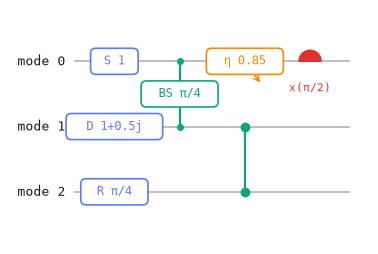

In [5]:
ax = c2.draw()

A bare `c2` in a notebook cell renders the same styled diagram inline
(via `_repr_svg_`):

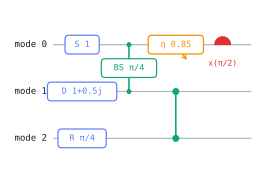

In [6]:
c2

## Passive interferometers and mesh decomposition

`interferometer(U)` applies an arbitrary passive unitary directly.
`decompositions.clements_decomposition(U)` breaks it into a physically
realizable mesh of beamsplitters and phase shifters -- the depth-optimal
**rectangular** mesh (Clements et al., Optica 3, 1460 (2016)), circuit
depth `n`, the standard choice in integrated/fibre photonics and this
package's recommended default. `decompositions.interferometer_mesh(U)`
gives the simpler but deeper (`2n-3`) **triangular** (Reck) mesh instead;
both return the same element format and are interchangeable.

In [7]:
n = 4
U = ops.random_interferometer(n, seed=0)
# extract the complex unitary back out of its symplectic (xpxp) embedding
x_idx, p_idx = np.arange(0, 2 * n, 2), np.arange(1, 2 * n, 2)
U_complex = U[np.ix_(x_idx, x_idx)] + 1j * U[np.ix_(p_idx, x_idx)]

elements = decompositions.clements_decomposition(U_complex)
n_phase = sum(1 for e in elements if e[0] == "phase")
n_bs = sum(1 for e in elements if e[0] == "bs")
print(f"{n}-mode interferometer -> {n_phase} phase shifters + {n_bs} beamsplitters (Clements mesh)")

4-mode interferometer -> 4 phase shifters + 6 beamsplitters (Clements mesh)


In [8]:
# rebuild the same interferometer as an explicit circuit of 2-mode elements,
# and check it reproduces the direct `interferometer(U)` call exactly
mesh_circuit = cv.Circuit(n)
for element in elements:
    if element[0] == "phase":
        _, mode, angle = element
        mesh_circuit.rotate(angle, mode=mode)
    else:
        _, mode1, mode2, theta, phi = element
        mesh_circuit.beamsplitter(theta, modes=(mode1, mode2), phi=phi)

direct = cv.random_state(n, pure=True, seed=1).interferometer(U_complex)
via_mesh = cv.random_state(n, pure=True, seed=1)
for element in elements:
    if element[0] == "phase":
        _, mode, angle = element
        via_mesh = via_mesh.rotate(angle, mode=mode)
    else:
        _, mode1, mode2, theta, phi = element
        via_mesh = via_mesh.beamsplitter(theta, modes=(mode1, mode2), phi=phi)

print("mesh reproduces direct interferometer:", np.allclose(direct.cov, via_mesh.cov, atol=1e-8))

mesh reproduces direct interferometer: True


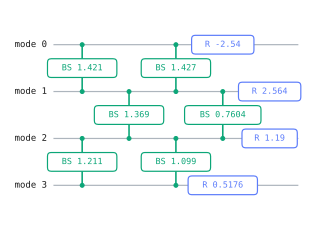

In [9]:
mesh_circuit

### Why Clements: depth

The same interferometer via the Reck (triangular) mesh takes measurably
more layers -- visible directly in `Circuit.depth()`, the same frontier
allocator the diagrams above use.

Clements depth: 5   Reck depth: 6   (n=4)


<Axes: >

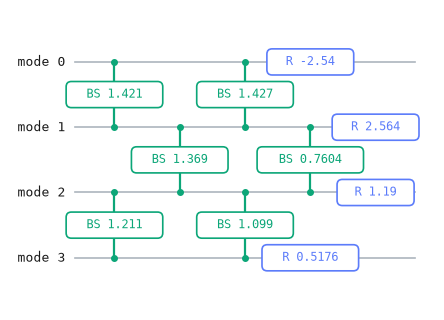

In [10]:
reck_elements = decompositions.interferometer_mesh(U_complex)
reck_circuit = cv.Circuit(n)
for element in reck_elements:
    if element[0] == "phase":
        _, mode, angle = element
        reck_circuit.rotate(angle, mode=mode)
    else:
        _, mode1, mode2, theta, phi = element
        reck_circuit.beamsplitter(theta, modes=(mode1, mode2), phi=phi)

print(f"Clements depth: {mesh_circuit.depth()}   Reck depth: {reck_circuit.depth()}   (n={n})")
mesh_circuit.draw()

## The Williamson and Bloch-Messiah decompositions

Any covariance matrix decomposes as `cov = S @ D @ S.T` (Williamson: `S`
symplectic, `D` diagonal symplectic eigenvalues); any symplectic matrix
decomposes as `S = O1 @ Z @ O2` (Bloch-Messiah: `O1, O2` passive
interferometers, `Z` single-mode squeezers) -- the "an arbitrary Gaussian
unitary is an interferometer, then independent squeezers, then another
interferometer" statement, made computational.

In [11]:
S_random = ops.random_symplectic(3, seed=2, max_squeezing=1.0)
O1, Z, O2 = decompositions.bloch_messiah(S_random)
print("reconstruction error:", np.max(np.abs(O1 @ Z @ O2 - S_random)))
print("squeezing factors (pairs e^r, e^-r):", np.diag(Z))

reconstruction error: 1.5543122344752192e-15
squeezing factors (pairs e^r, e^-r): [2.2574 0.443  1.3478 0.7419 1.0963 0.9122]
